<a href="https://colab.research.google.com/github/Madihasafi/ITC-300-Data-Visualization-/blob/main/Madiha_Safi%2C_Template_of_w9p2_Distributional_Analysis_with_Continuous_Data_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ITC 300 – Data Visualization
## w9p2 Assignment: Distributional Analysis with Continuous Data
### Dataset: `Salaries.csv`

This assignment applies the lecture concepts of **histograms, density plots, strip plots, and box plots** to the Salaries dataset.


## Learning Outcomes

After completing this assignment, you should be able to:

- preprocess a dataset before visualization;
- distinguish continuous and categorical variables;
- create and interpret histograms;
- distinguish count, relative frequency, and density;
- evaluate histogram sensitivity to bin choice;
- create and interpret kernel density plots;
- evaluate KDE sensitivity to bandwidth;
- create strip plots that preserve individual observations;
- calculate quartiles, IQR, fences, and possible outliers;
- create and interpret box plots;
- compare distributions across rank, discipline, and sex;
- recognize when compact summaries hide distribution shape;
- select a visualization according to the analytical question.


# **1. Import Required Libraries**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


# **2. Load the Dataset**

Upload `Salaries.csv` when Colab asks for the file.


In [2]:
import os

DATA_FILE = "Salaries.csv"

if not os.path.exists(DATA_FILE):
    from google.colab import files
    uploaded = files.upload()
    DATA_FILE = next(iter(uploaded))

df_raw = pd.read_csv(DATA_FILE)

print("Dataset shape:", df_raw.shape)
display(df_raw.head())


Saving Salaries.csv to Salaries.csv
Dataset shape: (397, 7)


,Unnamed: 0,rank,discipline,yrs.since.phd,yrs.service,sex,salary
0,1,Prof,B,19,18,Male,139750
1,2,Prof,B,20,16,Male,173200
2,3,AsstProf,B,4,3,Male,79750
3,4,Prof,B,45,39,Male,115000
4,5,Prof,B,40,41,Male,141500


# **3. Dataset Structure**

Relevant variables:

| Variable | Type | Description |
|---|---|---|
| `rank` | Categorical | Academic rank |
| `discipline` | Categorical | Discipline A or B |
| `yrs.since.phd` | Quantitative | Years since PhD |
| `yrs.service` | Quantitative | Years of service |
| `sex` | Categorical | Sex |
| `salary` | Continuous analytical variable | Faculty salary |


In [3]:
print("Columns:")
print(df_raw.columns.tolist())

print("\nData types:")
display(df_raw.dtypes.to_frame("dtype"))

print("\nDataset information:")
df_raw.info()


Columns:
['Unnamed: 0', 'rank', 'discipline', 'yrs.since.phd', 'yrs.service', 'sex', 'salary']

Data types:


,dtype
Unnamed: 0,int64
rank,object
discipline,object
yrs.since.phd,int64
yrs.service,int64
sex,object
salary,int64



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Unnamed: 0     397 non-null    int64 
 1   rank           397 non-null    object
 2   discipline     397 non-null    object
 3   yrs.since.phd  397 non-null    int64 
 4   yrs.service    397 non-null    int64 
 5   sex            397 non-null    object
 6   salary         397 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 21.8+ KB


# **Data Preprocessing**


## 4. Create a Working Copy and Remove the Export Index Column


In [4]:
df = df_raw.copy()

df = df.drop(columns=["Unnamed: 0"], errors="ignore")

print("Shape after removing non-analytical column:", df.shape)
display(df.head())


Shape after removing non-analytical column: (397, 6)


,rank,discipline,yrs.since.phd,yrs.service,sex,salary
0,Prof,B,19,18,Male,139750
1,Prof,B,20,16,Male,173200
2,AsstProf,B,4,3,Male,79750
3,Prof,B,45,39,Male,115000
4,Prof,B,40,41,Male,141500


## 5. Check Missing Values


In [5]:
missing = df.isna().sum().to_frame("missing_values")
missing["percent"] = (missing["missing_values"] / len(df) * 100).round(2)
display(missing)


,missing_values,percent
rank,0,0.0
discipline,0,0.0
yrs.since.phd,0,0.0
yrs.service,0,0.0
sex,0,0.0
salary,0,0.0


## 6. Check Duplicate Records


In [6]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 4


## 7. Clean and Standardize the Dataset


In [7]:
df = df.drop_duplicates().copy()

categorical_cols = ["rank", "discipline", "sex"]

for col in categorical_cols:
    df[col] = df[col].astype("string").str.strip()

numeric_cols = ["yrs.since.phd", "yrs.service", "salary"]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["rank", "discipline", "sex", "salary"])

print("Cleaned shape:", df.shape)
display(df.head())


Cleaned shape: (393, 6)


,rank,discipline,yrs.since.phd,yrs.service,sex,salary
0,Prof,B,19,18,Male,139750
1,Prof,B,20,16,Male,173200
2,AsstProf,B,4,3,Male,79750
3,Prof,B,45,39,Male,115000
4,Prof,B,40,41,Male,141500


## 8. Validate Categorical and Numerical Values


In [8]:
for col in categorical_cols:
    print(f"{col}: {sorted(df[col].dropna().unique().tolist())}")

display(df[numeric_cols].describe().T)


rank: ['AssocProf', 'AsstProf', 'Prof']
discipline: ['A', 'B']
sex: ['Female', 'Male']


,count,mean,std,min,25%,50%,75%,max
yrs.since.phd,393.0,22.503817,12.814637,1.0,12.0,21.0,32.0,56.0
yrs.service,393.0,17.755725,12.996129,0.0,7.0,17.0,27.0,60.0
salary,393.0,113930.844784,30360.608788,57800.0,91000.0,107500.0,134550.0,231545.0


In [10]:
invalid_numeric = (
    (df["salary"] < 0) |
    (df["yrs.since.phd"] < 0) |
    (df["yrs.service"] < 0)
)

print("Records with negative values:", invalid_numeric.sum())
display(df.loc[invalid_numeric])


Records with negative values: 0


,rank,discipline,yrs.since.phd,yrs.service,sex,salary


# **Chart Selection Guide**

| Visualization | Best Analytical Purpose | Information Preserved | Main Limitation |
|---|---|---|---|
| Histogram | Distribution shape and interval frequency | Counts or density by bin | Shape depends on binning |
| Density Plot | Smooth shape and group comparison | Estimated concentration | Hides raw counts |
| Strip Plot | Raw values and modest sample sizes | Individual observations | Can become crowded |
| Box Plot | Compact group comparison | Quartiles, IQR, whiskers, possible outliers | Hides modes and fine shape |


# **Assignment Exercises**

**Explain what each graph reveals and what it hides.**


### **Exercise 1**
Create histograms of `yrs.service` using 10, 20, and 30 bins. Compare the resulting shapes.

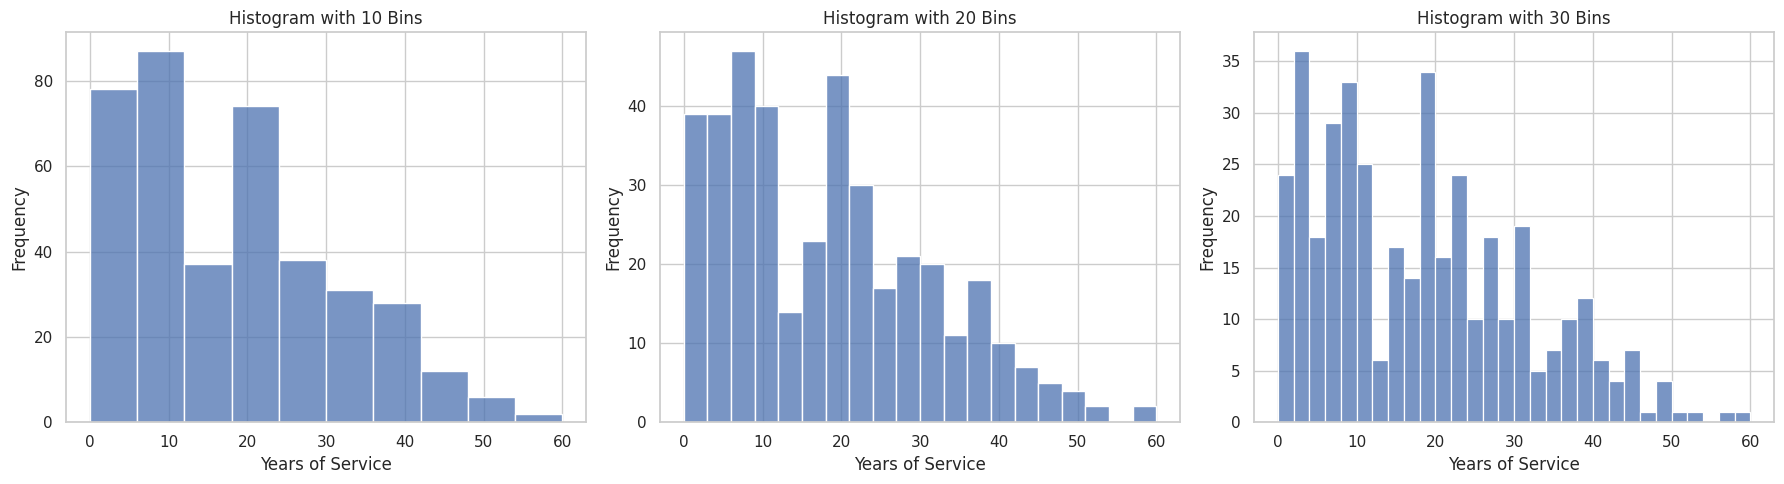

In [11]:
# Write your solution here

# Compare yrs.service distributions using 10, 20, and 30 bins

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

bin_counts = [10, 20, 30]

for ax, bins in zip(axes, bin_counts):
    sns.histplot(data=df, x="yrs.service", bins=bins, ax=ax)
    ax.set_title(f"Histogram with {bins} Bins")
    ax.set_xlabel("Years of Service")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

***Write your explanation here.***

Using 10 bins gives a general idea of how years of service are spread out, while using 20 or 30 bins shows more specific details. Adding more bins can show more clusters and spaces, but it might also make the histogram look less smooth. Using fewer bins gives a simpler look, but it might cover up key patterns. The way you choose the bins changes how you understand the distribution.

### **Exercise 2**
Create a density plot of `yrs.since.phd` using at least three bandwidth settings.

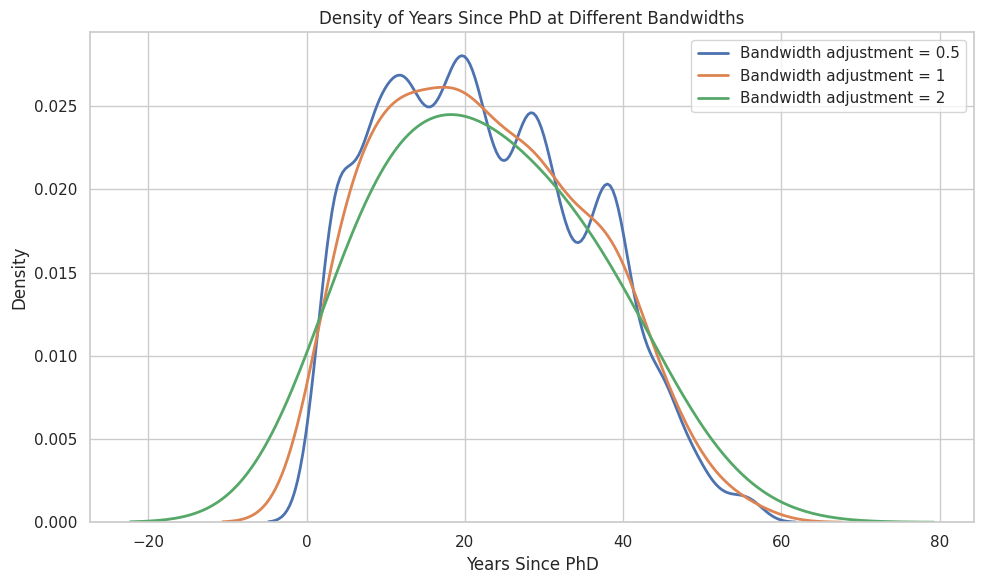

In [12]:
# Write your solution here

# Compare density estimates using different bandwidth settings

plt.figure(figsize=(10, 6))

for bandwidth in [0.5, 1, 2]:
    sns.kdeplot(
        data=df,
        x="yrs.since.phd",
        bw_adjust=bandwidth,
        label=f"Bandwidth adjustment = {bandwidth}",
        linewidth=2
    )

plt.title("Density of Years Since PhD at Different Bandwidths")
plt.xlabel("Years Since PhD")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()


***Write your explanation here.***

The density plot shows how spread out the years since getting a PhD are. Changing the bandwidth by 0.5 gives a more detailed but possibly uneven curve. A setting of 1 gives the standard amount of smoothing, but a setting of 2 makes the curve even smoother, which might make small peaks less noticeable. The way you choose bandwidth changes how the distribution looks, so you need to look at the plot carefully.

### **Exercise 3**
Create a strip plot of salary by discipline.

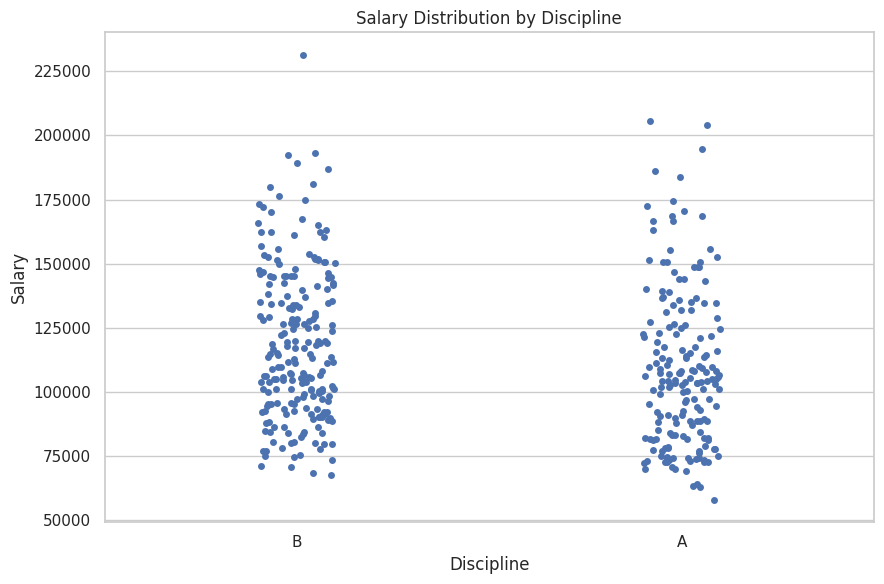

In [13]:
# Write your solution here

# Display individual salary observations by discipline

plt.figure(figsize=(9, 6))

sns.stripplot(
    data=df,
    x="discipline",
    y="salary",
    jitter=True
)

plt.title("Salary Distribution by Discipline")
plt.xlabel("Discipline")
plt.ylabel("Salary")
plt.tight_layout()
plt.show()


***Write your explanation here.***

The strip plot displays each person's salary in their specific field. It lets us look at salary ranges, see where most of the data points are, and spot any salaries that are much higher or lower than the rest. However, when many people have similar salaries, the overlapping points can make it hard to read the distribution. The plot doesn't explain quartiles in the same straightforward way that a box plot does.


### **Exercise 4**
Calculate the five-number summary and IQR for `yrs.service`.

In [14]:
# Write your solution here

# Calculate the five-number summary for years of service

five_number_summary = df["yrs.service"].describe(
    percentiles=[0.25, 0.50, 0.75]
).loc[["min", "25%", "50%", "75%", "max"]]

Q1 = df["yrs.service"].quantile(0.25)
median = df["yrs.service"].median()
Q3 = df["yrs.service"].quantile(0.75)
IQR = Q3 - Q1

print("Five-Number Summary:")
print(five_number_summary)

print("\nInterquartile Range (IQR):", IQR)


Five-Number Summary:
min     0.0
25%     7.0
50%    17.0
75%    27.0
max    60.0
Name: yrs.service, dtype: float64

Interquartile Range (IQR): 20.0


***Write your explanation here.***

The five-number summary includes the smallest value, the first quartile, the median, the third quartile, and the largest value. These numbers show the middle point and how much the years of service vary. The interquartile range is found by taking the third quartile and subtracting the first quartile from it. It shows how spread out the middle half of the data is and is not as influenced by very high or very low values as the full range.


### **Exercise 5**
Identify possible outliers in `yrs.service` using the 1.5 × IQR rule.

In [15]:
# Write your solution here

# Calculate the IQR and outlier fences

Q1 = df["yrs.service"].quantile(0.25)
Q3 = df["yrs.service"].quantile(0.75)
IQR = Q3 - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

# Identify observations outside the fences
outliers = df[
    (df["yrs.service"] < lower_fence) |
    (df["yrs.service"] > upper_fence)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower fence:", lower_fence)
print("Upper fence:", upper_fence)
print("Number of possible outliers:", len(outliers))

display(outliers[["rank", "discipline", "yrs.service", "salary"]])


Q1: 7.0
Q3: 27.0
IQR: 20.0
Lower fence: -23.0
Upper fence: 57.0
Number of possible outliers: 1


,rank,discipline,yrs.service,salary
330,Prof,B,60,192253


***Write your explanation here.***

The 1.5 times IQR rule finds possible outliers by setting lower and upper boundaries. Any service years value that is less than the lower limit or more than the upper limit is marked as flagged. These observations are far away from the middle 50% of the data, but that doesn't always mean they are mistakes. They need to be checked first before determining if any data should be deleted.


### **Exercise 6**
Create salary box plots by academic rank and discipline.

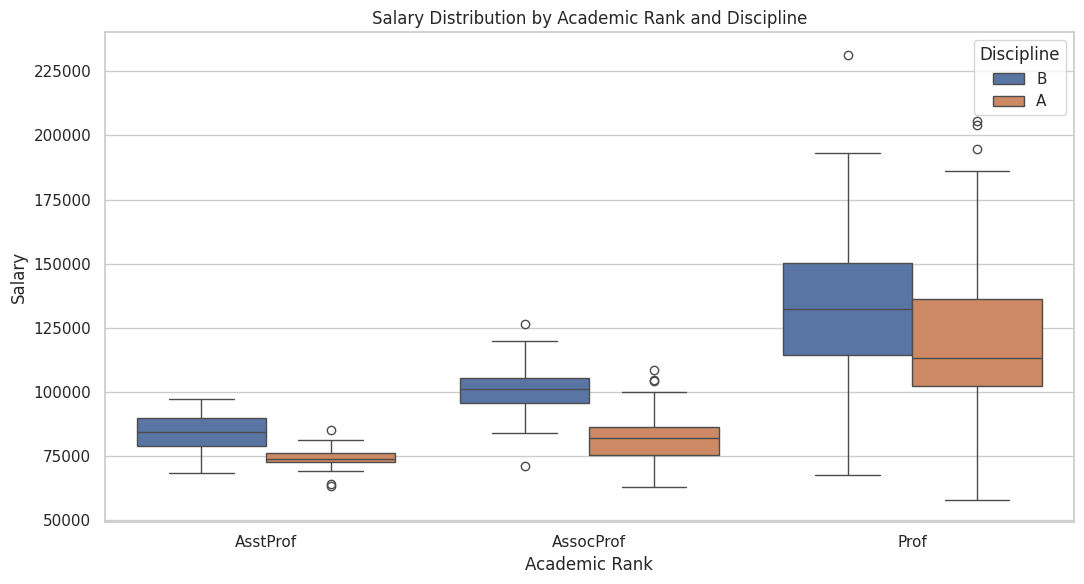

In [16]:
# Write your solution here

# Compare salary distributions by rank and discipline

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="rank",
    y="salary",
    hue="discipline",
    order=["AsstProf", "AssocProf", "Prof"]
)

plt.title("Salary Distribution by Academic Rank and Discipline")
plt.xlabel("Academic Rank")
plt.ylabel("Salary")
plt.legend(title="Discipline")
plt.tight_layout()
plt.show()


***Write your explanation here.***

The box plots show how salaries are spread out for different levels of academic positions and fields of study. The middle line shows the center of each group, and the box shows the middle 50% of the salaries. The whiskers show the spread of values in the box plot, and any separate points might be possible outliers. Comparing the data shows how much salaries differ and how much they vary, but box plots don't show all the details about how the salary amounts are spread out.

### **Exercise 7**
Choose one subgroup and display its distribution using:
- histogram;
- density plot;
- strip plot;
- box plot.

Subgroup size: 135


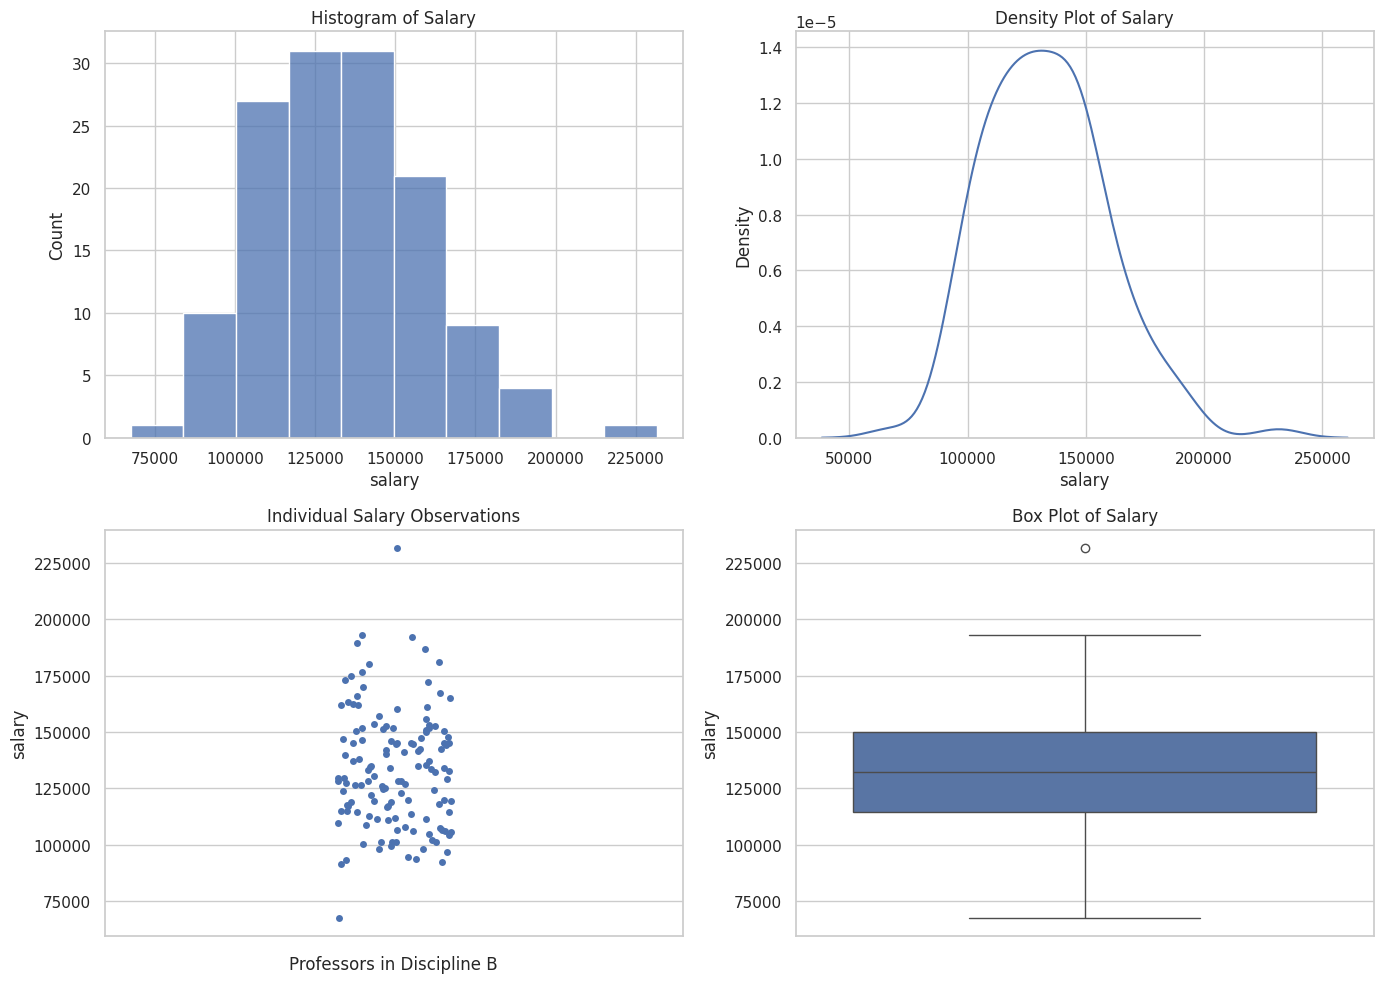

In [17]:
# Write your solution here

# Select one subgroup: Professors in Discipline B

subgroup = df[
    (df["rank"] == "Prof") &
    (df["discipline"] == "B")
].dropna(subset=["salary"])

print("Subgroup size:", len(subgroup))

if subgroup.empty:
    print("No observations found for this subgroup.")
else:
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # 1. Histogram
    sns.histplot(data=subgroup, x="salary", bins=10, ax=axes[0, 0])
    axes[0, 0].set_title("Histogram of Salary")

    # 2. Density plot
    sns.kdeplot(data=subgroup, x="salary", ax=axes[0, 1])
    axes[0, 1].set_title("Density Plot of Salary")

    # 3. Strip plot
    sns.stripplot(data=subgroup, y="salary", jitter=True, ax=axes[1, 0])
    axes[1, 0].set_title("Individual Salary Observations")
    axes[1, 0].set_xlabel("Professors in Discipline B")

    # 4. Box plot
    sns.boxplot(data=subgroup, y="salary", ax=axes[1, 1])
    axes[1, 1].set_title("Box Plot of Salary")

    plt.tight_layout()
    plt.show()


***Write your explanation here.***

The four graphs display various parts of the salary information for professors in Discipline B. The histogram shows how many salaries fall into each range, and the density plot shows the general pattern of how salaries are spread out. The strip plot shows each person's salary, and the box plot gives an overview of the middle value, the spread of the data, and any extreme values. Using all four plots gives a better overall picture than just using one visualization.